# YES BANK — Exploratory Data Analysis (EDA)

**Project type:** Exploratory Data Analysis (EDA)  
**Contribution:** Individual 
**Team members:** Rahul

## Project Summary

This project performs an end-to-end exploratory data analysis of the supplied YES BANK historical stock-price dataset. The objective is to understand the structure, quality, distribution, and relationships of the available monthly observations before any predictive modelling is attempted. The source file contains five fields: `Date`, `Open`, `High`, `Low`, and `Close`. The analysis uses the supplied data as its evidence base and does not add external market, company, news, or macroeconomic information.

The notebook begins by importing the Python libraries required for tabular analysis and visualization, locating the CSV file, and validating that the expected columns are present. It inspects the first and last records, dataset dimensions, data types, descriptive statistics, missing values, duplicate rows, unique values, and basic OHLC consistency. The date field is converted to a datetime value and records are sorted chronologically. Invalid date or price values are checked explicitly rather than silently coerced into usable observations. Duplicate rows are identified and removed, while inconsistent OHLC records or missing required values cause a clear validation error so that data problems are not hidden.

Feature engineering creates calendar fields (`Year`, `Month`, and `Month_Name`), the absolute trading range (`High - Low`), the opening-to-closing price change, the opening-to-closing percentage change, month-over-month closing return, absolute monthly return, percentage trading range, six-month and twelve-month moving averages, and twelve-month rolling return volatility. These derived variables make it possible to examine price level, return, and variability separately. The first monthly return is naturally undefined because there is no earlier observation against which to compare the first closing price; the rolling-volatility series also remains undefined until a complete rolling window is available.

The visualization section follows the UBM framework. Univariate analysis examines individual distributions and spreads. Bivariate analysis explores time-versus-price, year-versus-price, and numerical-versus-numerical relationships. Multivariate analysis combines several OHLC and engineered variables using correlation heatmaps, pair plots, and a year-month price matrix. Each of the 22 chart sections includes the visualization code, the reason for choosing the chart, observations supported by the supplied data, and potential business implications.

The dataset contains 185 monthly observations from July 2005 through November 2020. In the supplied file, the original five columns have no missing values or duplicate rows, and the high/low values are consistent with the opening and closing prices. The closing-price distribution is right-skewed. The average closing price is highest in 2017, while the 2020 observations represent only January through November and therefore should not be compared with a complete calendar year without qualification. The OHLC variables are very strongly positively correlated, which is useful descriptive information but also indicates potential multicollinearity if all are used together in a regression model. Monthly returns show substantial variation, including both large positive and negative observations, and rolling volatility changes over time.

The notebook ends with business-oriented recommendations, key limitations, and a conclusion. Its findings describe historical patterns; they do not establish the causes of price movements, provide investment advice, or guarantee future returns. A forecasting model would be a separate next phase and should use chronological validation, leakage-safe feature construction, suitable error metrics, and careful comparison against simple baselines.

## GitHub Link

https://github.com/Mr-rxa/yes-bank-ds

## Problem Statement

The objective is to explore the historical monthly OHLC (Open, High, Low, Close) prices of YES BANK, identify data-quality issues, understand price distributions and relationships, and discover historical patterns in price movement and return variability. The analysis should prepare the dataset for a later, properly validated closing-price forecasting exercise without claiming that exploratory patterns guarantee predictive performance.

### Define the Business Objective

Provide a clear, evidence-based view of historical YES BANK price behaviour that can support financial analysis and future model development. In particular, identify long-term price phases, unusual price movements, relationships among OHLC variables, and periods of higher or lower return variability. The analysis is descriptive and is not a recommendation to buy or sell the stock.

## General Guidelines and Methodology

- Keep code structured, reusable, and commented; use explicit validation and informative exceptions.
- Execute the notebook from top to bottom in a fresh Python/Jupyter kernel.
- Perform visual analysis using **UBM**: Univariate, Bivariate, and Multivariate analysis.
- Include at least 20 meaningful charts. This notebook contains 22, with a reason, observations, and business implication for every chart.
- Do not automatically remove genuine market extremes. Investigate unusual records before deciding whether they are data errors.
- Use chronological train/test validation in any future forecasting work; random splitting can leak temporal information.
- The supplied dataset has monthly OHLC prices only. It does not contain volume, dividends, company financials, benchmark indices, corporate-action details, or explanatory news variables.

# Let's Begin

## 1. Know Your Data

### Import Libraries

In [1]:
# Core data handling
from pathlib import Path
import warnings

import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Display and reproducibility settings
from IPython.display import display

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 140)
pd.set_option('display.float_format', lambda value: f'{value:,.3f}')

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

RANDOM_STATE = 42  # Reserved for reproducible operations if sampling is added later.
print('Libraries imported successfully.')

Libraries imported successfully.


### Dataset Loading

In [2]:
# Keep the CSV in the same folder as this notebook for the most portable setup.
# A few common working-directory locations are also checked for convenience.
DATA_FILE = 'data_YesBank_StockPrices.csv'
search_locations = [
    Path.cwd() / DATA_FILE,
    Path.cwd() / 'Downloads' / 'yes_bank' / DATA_FILE,
    Path('/mnt/data') / DATA_FILE,  # Useful in hosted notebook environments.
]

DATA_PATH = next((candidate for candidate in search_locations if candidate.is_file()), None)
if DATA_PATH is None:
    searched = '\n'.join(str(path) for path in search_locations)
    raise FileNotFoundError(
        f"Could not find {DATA_FILE}. Place the CSV beside this notebook. Searched:\n{searched}"
    )

try:
    raw_df = pd.read_csv(DATA_PATH)
except (pd.errors.ParserError, UnicodeDecodeError, OSError) as exc:
    raise RuntimeError(f'Unable to read the dataset at {DATA_PATH}: {exc}') from exc

print(f'Dataset loaded from: {DATA_PATH.resolve()}')
print(f'Raw dataset shape: {raw_df.shape}')

Dataset loaded from: C:\Users\sharm\Downloads\yes_bank\data_YesBank_StockPrices.csv
Raw dataset shape: (185, 5)


### Dataset First View

In [3]:
# Inspect a few records from the beginning and end of the source file.
display(raw_df.head())
display(raw_df.tail())

,Date,Open,High,Low,Close
0,Jul-05,13.000,14.000,11.250,12.460
1,Aug-05,12.580,14.880,12.550,13.420
2,Sep-05,13.480,14.870,12.270,13.300
3,Oct-05,13.200,14.470,12.400,12.990
4,Nov-05,13.350,13.880,12.880,13.410


,Date,Open,High,Low,Close
180,Jul-20,25.600,28.300,11.100,11.950
181,Aug-20,12.000,17.160,11.850,14.370
182,Sep-20,14.300,15.340,12.750,13.150
183,Oct-20,13.300,14.010,12.110,12.420
184,Nov-20,12.410,14.900,12.210,14.670


### Dataset Rows and Columns Count

In [4]:
# Report the dimensions of the original dataset.
row_count, column_count = raw_df.shape
print(f'Number of rows: {row_count}')
print(f'Number of columns: {column_count}')
print(f'Dataset shape: {raw_df.shape}')

Number of rows: 185
Number of columns: 5
Dataset shape: (185, 5)


### Dataset Information

In [5]:
# Show source column types and non-null counts.
raw_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 185 entries, 0 to 184
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    185 non-null    str    
 1   Open    185 non-null    float64
 2   High    185 non-null    float64
 3   Low     185 non-null    float64
 4   Close   185 non-null    float64
dtypes: float64(4), str(1)
memory usage: 8.4 KB


### Duplicate Values

In [6]:
# Count complete duplicate rows in the raw source data.
duplicate_count = int(raw_df.duplicated().sum())
print(f'Number of duplicate rows: {duplicate_count}')
if duplicate_count:
    display(raw_df.loc[raw_df.duplicated(keep=False)].head(10))
else:
    print('No duplicate rows found.')

Number of duplicate rows: 0
No duplicate rows found.


### Missing Values / Null Values

In [7]:
# Count missing values in every original column.
missing_by_column = raw_df.isna().sum()
display(missing_by_column.to_frame('Missing Values'))
print(f'Total missing cells: {int(missing_by_column.sum())}')

,Missing Values
Date,0
Open,0
High,0
Low,0
Close,0


Total missing cells: 0


### Visualizing Missing Values

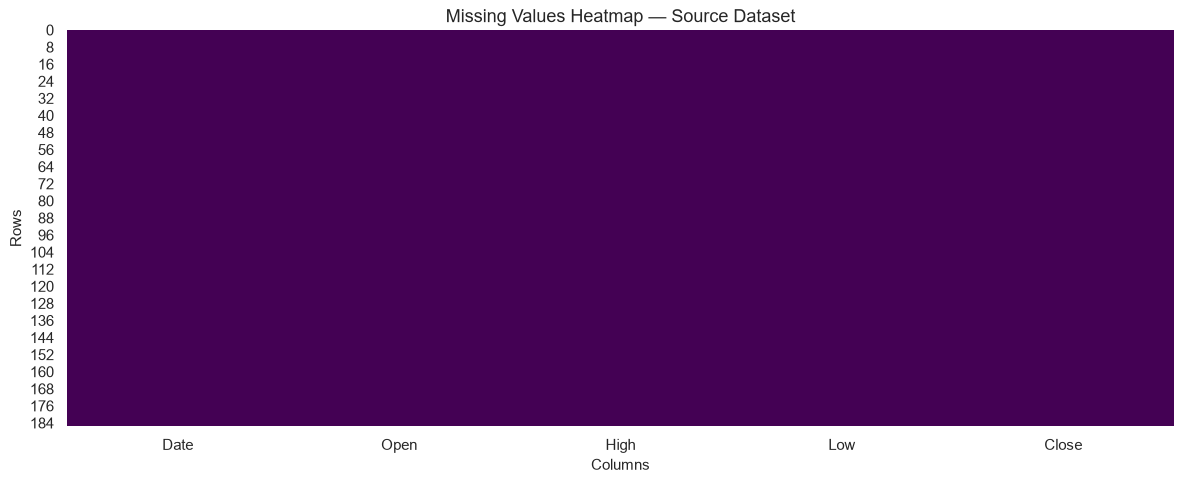

In [8]:
# A heatmap makes missing-value patterns easy to see.
plt.figure(figsize=(12, 5))
sns.heatmap(raw_df.isna(), cbar=False, cmap='viridis')
plt.title('Missing Values Heatmap — Source Dataset')
plt.xlabel('Columns')
plt.ylabel('Rows')
plt.tight_layout()
plt.show()
plt.close()

### What did you learn about the dataset?

The supplied file has **185 rows and 5 columns**: `Date`, `Open`, `High`, `Low`, and `Close`. The observations run from **July 2005 to November 2020**. The four price columns are numeric, while `Date` is initially stored as text. The raw file has **zero missing cells and zero duplicate rows**. Additional validity checks are performed during data wrangling before derived features are created.

## 2. Understanding Your Variables

### Dataset Columns and Descriptive Statistics

In [9]:
print('Dataset columns:')
print(raw_df.columns.tolist())

print('\nDescriptive statistics for numeric variables:')
display(raw_df.describe())

print('\nDescriptive statistics including the date field:')
display(raw_df.describe(include='all'))

Dataset columns:
['Date', 'Open', 'High', 'Low', 'Close']

Descriptive statistics for numeric variables:


,Open,High,Low,Close
count,185.000,185.000,185.000,185.000
mean,105.541,116.104,94.948,105.205
std,98.880,106.333,91.219,98.583
min,10.000,11.240,5.550,9.980
25%,33.800,36.140,28.510,33.450
50%,62.980,72.550,58.000,62.540
75%,153.000,169.190,138.350,153.300
max,369.950,404.000,345.500,367.900



Descriptive statistics including the date field:


,Date,Open,High,Low,Close
count,185,185.000,185.000,185.000,185.000
unique,185,NaN,NaN,NaN,NaN
top,Jul-05,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,NaN
mean,NaN,105.541,116.104,94.948,105.205
std,NaN,98.880,106.333,91.219,98.583
min,NaN,10.000,11.240,5.550,9.980
25%,NaN,33.800,36.140,28.510,33.450
50%,NaN,62.980,72.550,58.000,62.540
75%,NaN,153.000,169.190,138.350,153.300


### Variables Description

| Variable | Description | Source type | Analytical role |
|---|---|---|---|
| `Date` | Month and year of the observation | Object/string initially | Time index |
| `Open` | Opening price for the observation period | Numeric | OHLC predictor / descriptive variable |
| `High` | Highest price recorded during the period | Numeric | OHLC predictor / descriptive variable |
| `Low` | Lowest price recorded during the period | Numeric | OHLC predictor / descriptive variable |
| `Close` | Closing price for the observation period | Numeric | Main variable of interest; potential forecast target |

The CSV itself does not contain a currency column. The charts use ₹ labels in keeping with the assignment context; the currency should be confirmed from the original source metadata before the analysis is shared externally.

### Check Unique Values for Each Variable

In [10]:
# nunique() counts distinct non-null values in each source column.
unique_counts = raw_df.nunique(dropna=True).rename('Unique Values')
display(unique_counts.to_frame())

,Unique Values
Date,185
Open,183
High,184
Low,183
Close,185


## 3. Data Wrangling

### Data Validation and Cleaning

In [11]:
# Work on a copy so the originally loaded source data remains unchanged.
df = raw_df.copy()
df.columns = df.columns.astype(str).str.strip()

required_columns = ['Date', 'Open', 'High', 'Low', 'Close']
missing_columns = [column for column in required_columns if column not in df.columns]
if missing_columns:
    raise ValueError(f'The dataset is missing required columns: {missing_columns}')

# Keep only the required assignment fields and preserve their expected order.
df = df[required_columns].copy()

# Parse dates using the supplied file's month-year format (for example, Jul-05).
parsed_dates = pd.to_datetime(df['Date'].astype(str).str.strip(), format='%b-%y', errors='coerce')
invalid_date_count = int(parsed_dates.isna().sum())
if invalid_date_count:
    bad_values = df.loc[parsed_dates.isna(), 'Date'].head(5).tolist()
    raise ValueError(f'Found {invalid_date_count} invalid Date values. Examples: {bad_values}')
df['Date'] = parsed_dates

# Convert prices to numeric; errors become NaN and are explicitly checked below.
for column in ['Open', 'High', 'Low', 'Close']:
    df[column] = pd.to_numeric(df[column], errors='coerce')

missing_after_conversion = df[required_columns].isna().sum()
if int(missing_after_conversion.sum()):
    raise ValueError(
        'Missing or non-numeric required values found after conversion:\n'
        + missing_after_conversion[missing_after_conversion > 0].to_string()
    )

# Remove complete duplicate rows if present and report the action.
duplicates_before = int(df.duplicated().sum())
if duplicates_before:
    df = df.drop_duplicates().copy()
print(f'Complete duplicate rows removed: {duplicates_before}')

# A monthly time series should have one observation per month.
if df['Date'].duplicated().any():
    duplicate_dates = df.loc[df['Date'].duplicated(keep=False), 'Date'].dt.strftime('%b-%Y').tolist()
    raise ValueError(f'Multiple records found for the same month: {duplicate_dates[:10]}')

# Sort before calculating any time-dependent features.
df = df.sort_values('Date').reset_index(drop=True)

# Validate numeric domain and OHLC ordering.
price_columns = ['Open', 'High', 'Low', 'Close']
if (df[price_columns] <= 0).any().any():
    raise ValueError('Non-positive stock prices were found; review the source data.')

invalid_high = df['High'] < df[['Open', 'Close']].max(axis=1)
invalid_low = df['Low'] > df[['Open', 'Close']].min(axis=1)
invalid_range = df['High'] < df['Low']
invalid_ohlc_count = int((invalid_high | invalid_low | invalid_range).sum())
if invalid_ohlc_count:
    raise ValueError(f'{invalid_ohlc_count} records violate OHLC ordering; inspect the source data.')

print(f'Validated dataset shape: {df.shape}')
print(f'Date range: {df.Date.min():%b %Y} to {df.Date.max():%b %Y}')
print('OHLC consistency check: passed.')
display(df.head())

Complete duplicate rows removed: 0
Validated dataset shape: (185, 5)
Date range: Jul 2005 to Nov 2020
OHLC consistency check: passed.


,Date,Open,High,Low,Close
0,2005-07-01,13.000,14.000,11.250,12.460
1,2005-08-01,12.580,14.880,12.550,13.420
2,2005-09-01,13.480,14.870,12.270,13.300
3,2005-10-01,13.200,14.470,12.400,12.990
4,2005-11-01,13.350,13.880,12.880,13.410


### Feature Engineering

In [12]:
# Calendar fields support yearly and month-of-year summaries.
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Month_Name'] = df['Date'].dt.strftime('%b')

# Absolute and percentage measures of within-period price movement.
df['Price_Range'] = df['High'] - df['Low']
df['Price_Change'] = df['Close'] - df['Open']
df['Price_Change_Pct'] = np.where(
    df['Open'].ne(0), df['Price_Change'] / df['Open'] * 100, np.nan
)
df['Price_Range_Pct'] = np.where(
    df['Close'].ne(0), df['Price_Range'] / df['Close'] * 100, np.nan
)

# Month-over-month return uses the prior month's close; the first value is undefined by definition.
df['Monthly_Return'] = df['Close'].pct_change(fill_method=None) * 100
df['Absolute_Return'] = df['Monthly_Return'].abs()

# Trailing moving averages and volatility use only current and prior observations.
df['MA_6'] = df['Close'].rolling(window=6, min_periods=6).mean()
df['MA_12'] = df['Close'].rolling(window=12, min_periods=12).mean()
df['Rolling_Volatility'] = df['Monthly_Return'].rolling(window=12, min_periods=12).std()

print('Feature engineering complete.')
print('The first monthly return is NaN because no preceding month is available.')
print('Rolling measures remain NaN until a full 12-observation window is available.')
display(df.head(15))

Feature engineering complete.
The first monthly return is NaN because no preceding month is available.
Rolling measures remain NaN until a full 12-observation window is available.


,Date,Open,High,Low,Close,Year,Month,Month_Name,Price_Range,Price_Change,Price_Change_Pct,Price_Range_Pct,Monthly_Return,Absolute_Return,MA_6,MA_12,Rolling_Volatility
0,2005-07-01,13.000,14.000,11.250,12.460,2005,7,Jul,2.750,-0.540,-4.154,22.071,NaN,NaN,NaN,NaN,NaN
1,2005-08-01,12.580,14.880,12.550,13.420,2005,8,Aug,2.330,0.840,6.677,17.362,7.705,7.705,NaN,NaN,NaN
2,2005-09-01,13.480,14.870,12.270,13.300,2005,9,Sep,2.600,-0.180,-1.335,19.549,-0.894,0.894,NaN,NaN,NaN
3,2005-10-01,13.200,14.470,12.400,12.990,2005,10,Oct,2.070,-0.210,-1.591,15.935,-2.331,2.331,NaN,NaN,NaN
4,2005-11-01,13.350,13.880,12.880,13.410,2005,11,Nov,1.000,0.060,0.449,7.457,3.233,3.233,NaN,NaN,NaN
5,2005-12-01,13.490,14.440,13.000,13.710,2005,12,Dec,1.440,0.220,1.631,10.503,2.237,2.237,13.215,NaN,NaN
6,2006-01-01,13.680,17.160,13.580,15.330,2006,1,Jan,3.580,1.650,12.061,23.353,11.816,11.816,13.693,NaN,NaN
7,2006-02-01,15.500,16.970,15.400,16.120,2006,2,Feb,1.570,0.620,4.000,9.739,5.153,5.153,14.143,NaN,NaN
8,2006-03-01,16.200,20.950,16.020,20.080,2006,3,Mar,4.930,3.880,23.951,24.552,24.566,24.566,15.273,NaN,NaN
9,2006-04-01,20.560,20.800,18.020,19.490,2006,4,Apr,2.780,-1.070,-5.204,14.264,-2.938,2.938,16.357,NaN,NaN


### Data Wrangling — What was changed and what was learned?

1. Selected the five required source columns and standardized column-name whitespace.
2. Converted `Date` from text into a datetime value and sorted records chronologically.
3. Converted OHLC fields to numeric values and raised an explicit error if an invalid or missing value was encountered.
4. Checked duplicate dates, duplicate rows, positive prices, and OHLC ordering. In the supplied CSV, no duplicate rows or invalid OHLC records were found.
5. Extracted `Year`, `Month`, and `Month_Name` for calendar-based analysis.
6. Added `Price_Range`, `Price_Change`, `Price_Change_Pct`, and `Price_Range_Pct` to describe within-period price movement.
7. Added `Monthly_Return`, `Absolute_Return`, six- and twelve-month moving averages, and twelve-month rolling volatility. The first return and early rolling observations are naturally undefined rather than imputed.

The prepared data contains **185 chronological monthly records**. These derived features enable analysis of price levels, absolute and relative movements, and trailing variability without using future observations in the moving calculations.

### Prepared Dataset Summary

In [13]:
# Summarize the engineered data and check that key input features remain valid.
display(df[['Open', 'High', 'Low', 'Close', 'Price_Range', 'Price_Change_Pct', 'Monthly_Return', 'Rolling_Volatility']].describe().T)
print('Rows:', len(df))
print('Date range:', df['Date'].min().date(), 'to', df['Date'].max().date())
print('Monthly returns available:', int(df['Monthly_Return'].notna().sum()))
print('Duplicate rows after preparation:', int(df.duplicated().sum()))

,count,mean,std,min,25%,50%,75%,max
Open,185.000,105.541,98.880,10.000,33.800,62.980,153.000,369.950
High,185.000,116.104,106.333,11.240,36.140,72.550,169.190,404.000
Low,185.000,94.948,91.219,5.550,28.510,58.000,138.350,345.500
Close,185.000,105.205,98.583,9.980,33.450,62.540,153.300,367.900
Price_Range,185.000,21.156,23.453,1.000,7.100,13.450,25.830,183.850
Price_Change_Pct,185.000,1.036,16.385,-53.320,-6.617,1.106,8.741,67.738
Monthly_Return,184.000,1.497,16.534,-53.320,-5.608,2.196,8.448,69.964
Rolling_Volatility,173.000,14.567,7.048,4.908,9.704,11.440,17.573,32.836


Rows: 185
Date range: 2005-07-01 to 2020-11-01
Monthly returns available: 184
Duplicate rows after preparation: 0


## 4. Data Visualization, Storytelling, and Experimenting with Charts

The charts below are organized using the **UBM rule**. The first six charts are Univariate, the next twelve are Bivariate, and the final four are Multivariate. Every chart is followed by the selection rationale, actual observations, and business implications.

### U — Univariate Analysis

#### Chart 1 — Distribution of Closing Prices (Histogram and KDE)

**Chart visualization code**

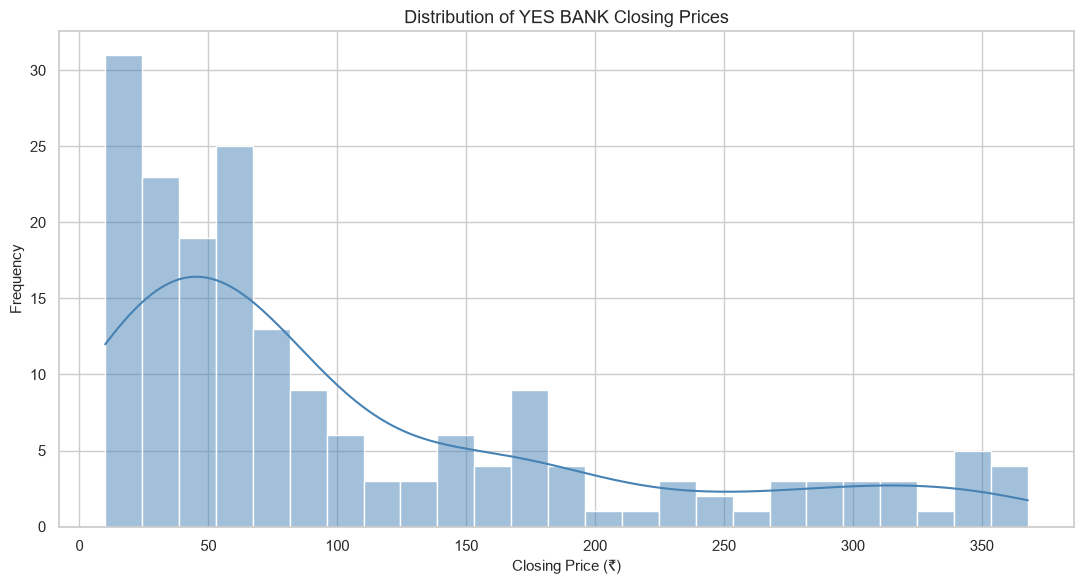

In [14]:
# Chart 1: Inspect the distribution of the closing-price variable.
plt.figure(figsize=(11, 6))
sns.histplot(data=df, x='Close', bins=25, kde=True, color='steelblue')
plt.title('Distribution of YES BANK Closing Prices')
plt.xlabel('Closing Price (₹)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()
plt.close()

**1. Why did you pick the specific chart?**

A histogram with a KDE curve was selected because it shows both the frequency of closing-price ranges and the smoothed shape of the distribution. It is useful for checking concentration, skewness, and the presence of a long tail.

**2. What are the insights found from the chart?**

The closing prices range from **₹9.98 to ₹367.90**. The mean is approximately **₹105.20**, while the median is **₹62.54**. The distribution is right-skewed (skewness approximately **1.26**): many observations occur at lower price levels, with fewer observations at much higher levels. This is consistent with the dataset covering a long period in which the stock's overall price level changed substantially.

**3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.**

The distribution helps analysts understand typical historical price levels and recognize that the mean is pulled upward by higher-price periods. This is useful context for descriptive reporting and model evaluation. The right tail is not itself evidence of a data error or of a future price increase; time ordering must be considered because the observations span many years.

#### Chart 2 — OHLC Price Distribution (Box Plot)

**Chart visualization code**

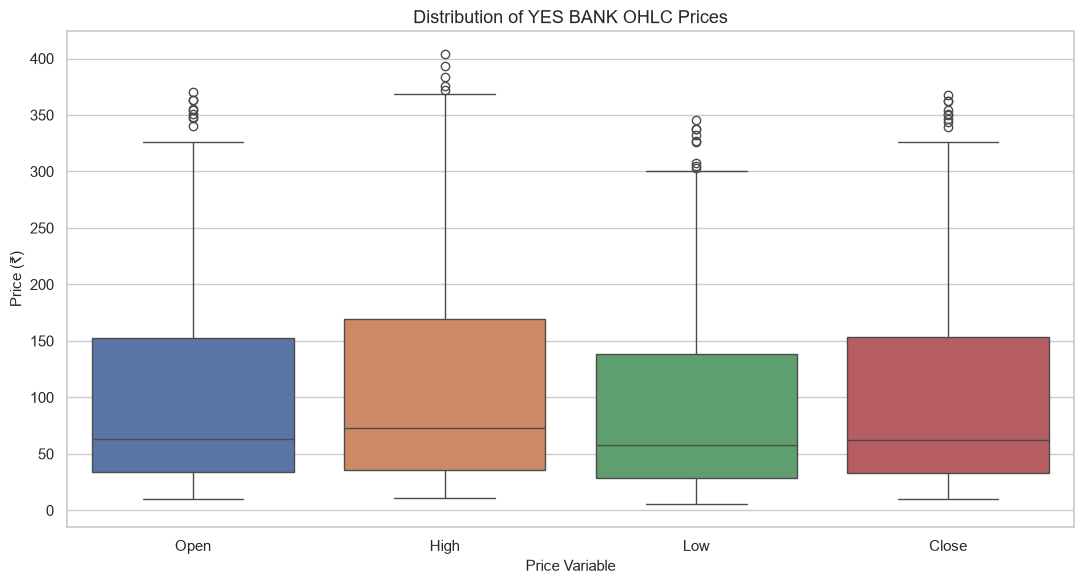

In [15]:
# Chart 2: Compare the distributions and potential extreme observations across OHLC variables.
plt.figure(figsize=(11, 6))
sns.boxplot(data=df[['Open', 'High', 'Low', 'Close']])
plt.title('Distribution of YES BANK OHLC Prices')
plt.xlabel('Price Variable')
plt.ylabel('Price (₹)')
plt.tight_layout()
plt.show()
plt.close()

**1. Why did you pick the specific chart?**

A box plot was chosen to compare medians, interquartile ranges, and potential extreme observations across the four OHLC price variables in one view.

**2. What are the insights found from the chart?**

The OHLC variables have broadly similar distributions because they represent prices for the same stock and month. `High` tends to sit above the other price measures and `Low` below them by definition. The spread is wide because the data spans 2005–2020, during which the overall stock-price level changed considerably. Any points beyond the whiskers should be investigated, not automatically removed.

**3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.**

The comparison highlights differences in price spread and prompts data-quality checks before modelling. Genuine market extremes may be important events; removing them without evidence could discard useful information. Since the variables have similar price scales, this chart is suitable for comparing their distributions.

#### Chart 3 — Closing Price Distribution (Violin Plot)

**Chart visualization code**

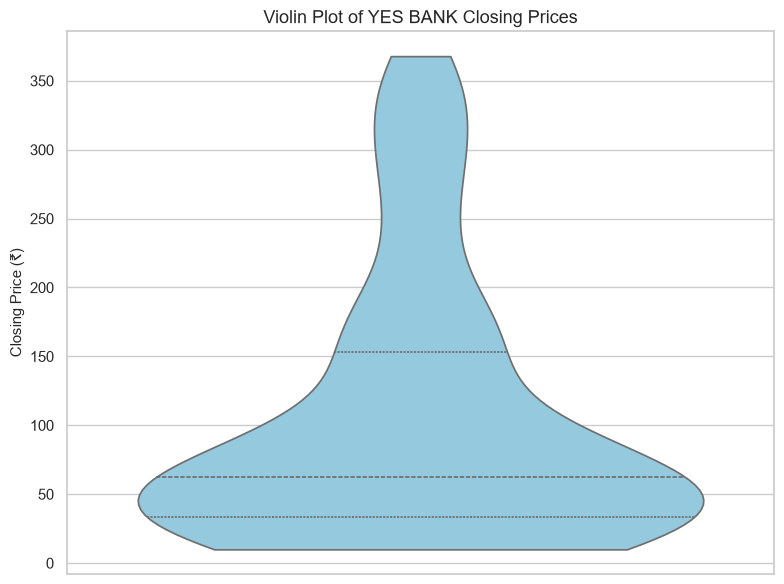

In [16]:
# Chart 3: View the distribution density and quartiles for closing prices.
plt.figure(figsize=(8, 6))
sns.violinplot(y=df['Close'], inner='quartile', color='skyblue', cut=0)
plt.title('Violin Plot of YES BANK Closing Prices')
plt.ylabel('Closing Price (₹)')
plt.tight_layout()
plt.show()
plt.close()

**1. Why did you pick the specific chart?**

A violin plot was selected to show the density shape of closing prices together with the median and quartiles. It complements the histogram and box plot by making areas of greater observation density visible.

**2. What are the insights found from the chart?**

The plot reflects the right-skewed closing-price distribution: observations are more concentrated at lower price levels, while fewer observations extend to the high-price range. The closing-price median is **₹62.54**, below the mean of approximately **₹105.20**. The density shape reflects several historical price regimes rather than a single stable price distribution.

**3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.**

Recognizing the non-symmetric distribution helps analysts avoid relying on a single average as a complete description of the data. It can inform the choice of robust summaries and model diagnostics. The density shape does not identify the timing or cause of price changes, so it should be read alongside time-series charts.

#### Chart 4 — Distribution of Monthly Returns

**Chart visualization code**

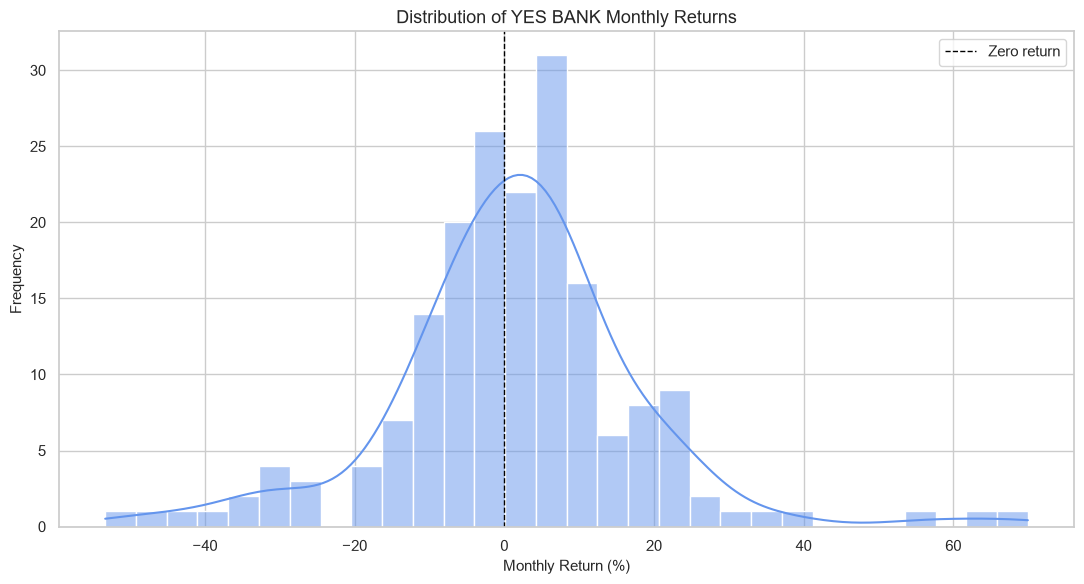

In [17]:
# Chart 4: Examine the frequency and spread of month-over-month closing returns.
plt.figure(figsize=(11, 6))
sns.histplot(data=df, x='Monthly_Return', bins=30, kde=True, color='cornflowerblue')
plt.axvline(0, color='black', linestyle='--', linewidth=1, label='Zero return')
plt.title('Distribution of YES BANK Monthly Returns')
plt.xlabel('Monthly Return (%)')
plt.ylabel('Frequency')
plt.legend()
plt.tight_layout()
plt.show()
plt.close()

**1. Why did you pick the specific chart?**

A histogram with a KDE curve was chosen to show how frequently monthly returns fall within different ranges and whether returns are symmetric around zero. The zero line distinguishes positive from negative months.

**2. What are the insights found from the chart?**

There are **184 valid monthly returns**: **101 positive** and **83 negative**. The mean monthly return is approximately **1.50%**, the median is **2.20%**, and the standard deviation is approximately **16.53 percentage points**. Observed returns range from **−53.32%** to **+69.96%**, so the distribution includes extreme movements in both directions.

**3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.**

This view supports historical risk assessment and helps identify the presence of extreme monthly outcomes that may matter for model evaluation. The large spread and extreme observations indicate that average return alone is not enough to characterize risk. A histogram cannot predict the next return or establish why an extreme movement occurred.

#### Chart 5 — Distribution of Monthly Trading Range

**Chart visualization code**

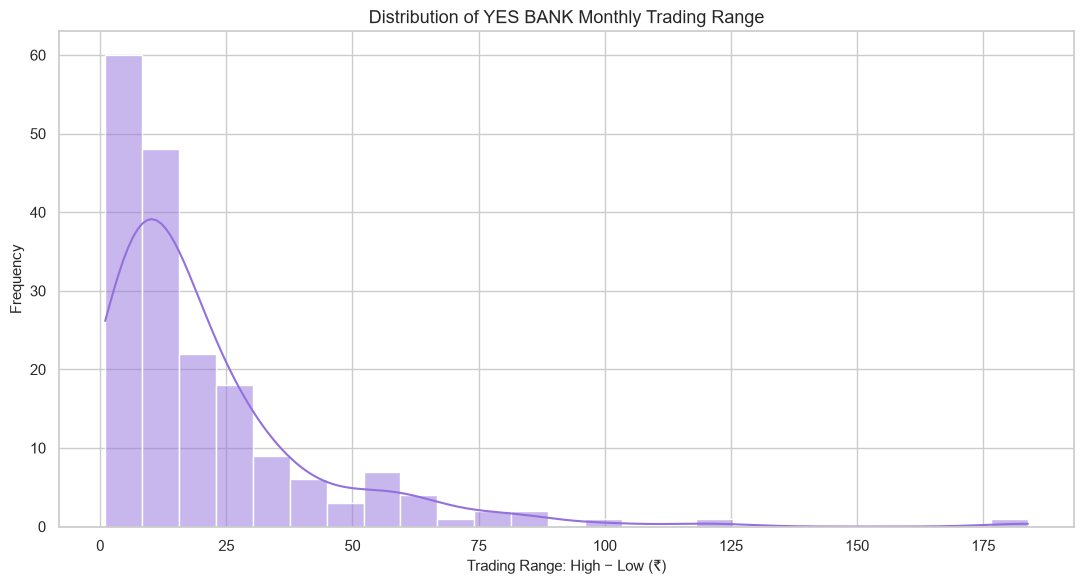

In [18]:
# Chart 5: Examine the absolute difference between each month's High and Low.
plt.figure(figsize=(11, 6))
sns.histplot(data=df, x='Price_Range', bins=25, kde=True, color='mediumpurple')
plt.title('Distribution of YES BANK Monthly Trading Range')
plt.xlabel('Trading Range: High − Low (₹)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()
plt.close()

**1. Why did you pick the specific chart?**

A histogram with KDE was selected to inspect the distribution of the monthly high-low range. This feature measures the absolute within-month spread and helps identify periods with unusually wide ranges.

**2. What are the insights found from the chart?**

The trading range has a mean of approximately **₹21.16** and a median of **₹13.45**. It ranges from **₹1.00 to ₹183.85**. The maximum range occurs in **September 2018**, illustrating that a small number of observations have much wider absolute ranges than the typical month.

**3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.**

The chart helps identify observations for further review and supports development of risk indicators. Because an absolute range can naturally be larger when the stock price is higher, analysts should also consider percentage range when comparing periods with very different price levels. A wide range alone does not show whether the month ended with a gain or a loss.

#### Chart 6 — Distribution of 12-Month Rolling Volatility

**Chart visualization code**

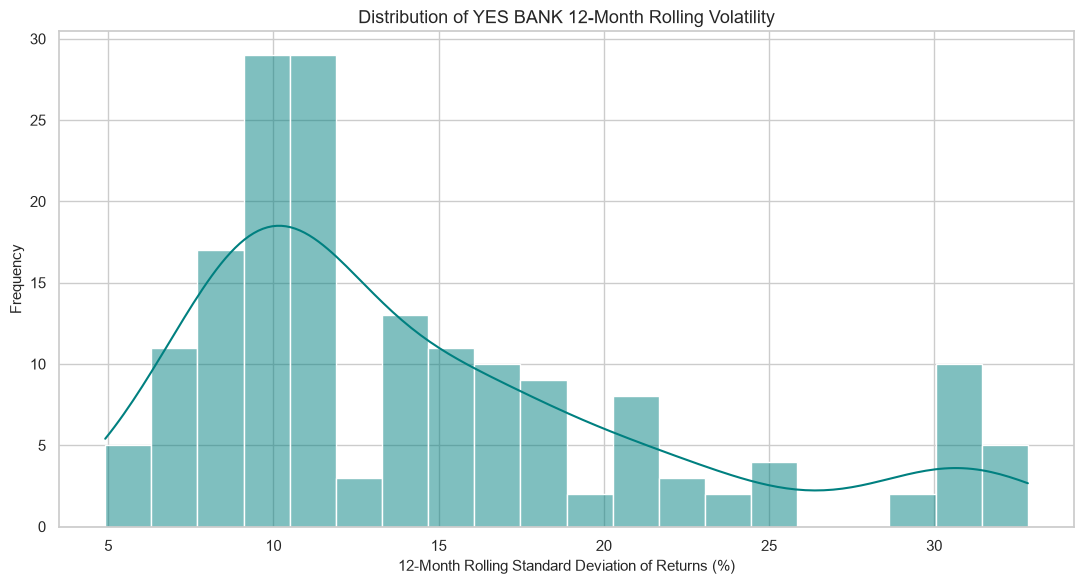

In [19]:
# Chart 6: Inspect the distribution of the trailing standard deviation of monthly returns.
plt.figure(figsize=(11, 6))
sns.histplot(data=df, x='Rolling_Volatility', bins=20, kde=True, color='teal')
plt.title('Distribution of YES BANK 12-Month Rolling Volatility')
plt.xlabel('12-Month Rolling Standard Deviation of Returns (%)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()
plt.close()

**1. Why did you pick the specific chart?**

A histogram with KDE was selected to examine the distribution of trailing 12-month return volatility. It summarizes how often different levels of historical variability occurred.

**2. What are the insights found from the chart?**

The valid rolling-volatility values range from approximately **4.91% to 32.84%**. The maximum is recorded in **August 2020**. The first part of the series is undefined until a complete twelve-month return window is available, which is expected for a rolling statistic.

**3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.**

The distribution helps describe how often the stock experienced relatively calm or highly variable trailing periods. It can inform risk-monitoring thresholds and model stress testing. High volatility is about the magnitude of return variation, not its direction; it can accompany gains or losses.

### B — Bivariate Analysis

#### Chart 7 — OHLC Prices Over Time

**Chart visualization code**

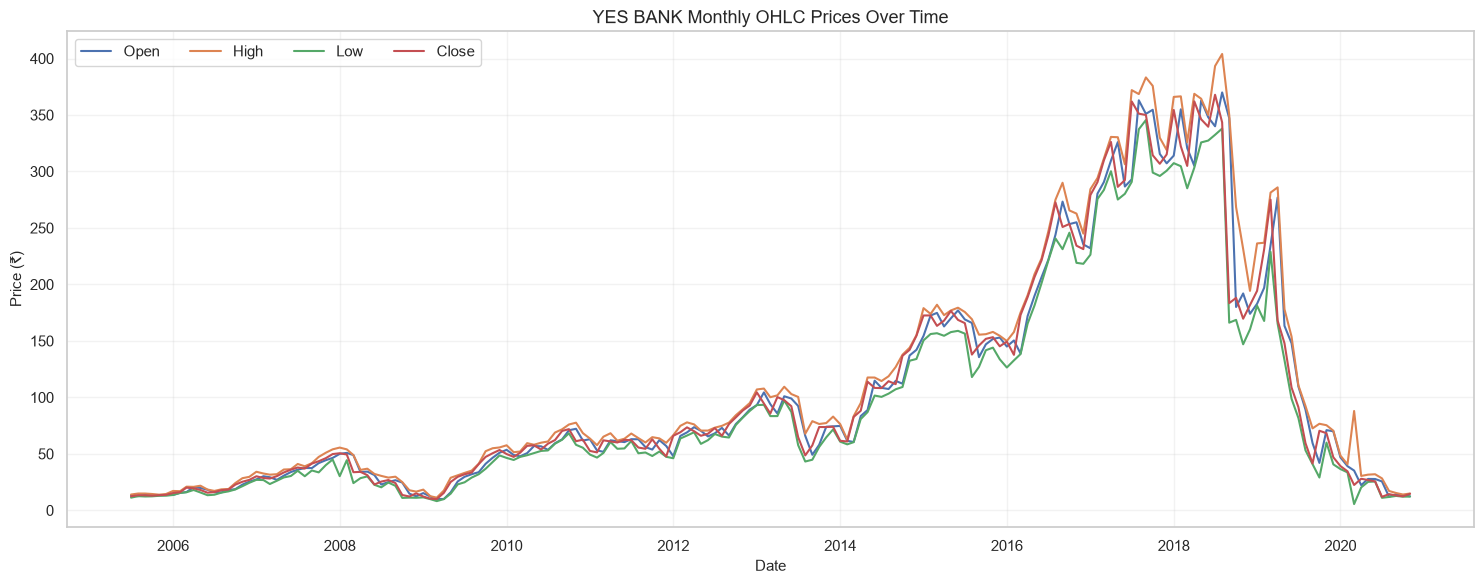

In [20]:
# Chart 7: Compare the four monthly OHLC price series across the observation period.
plt.figure(figsize=(15, 6))
for column in ['Open', 'High', 'Low', 'Close']:
    plt.plot(df['Date'], df[column], label=column, linewidth=1.5)
plt.title('YES BANK Monthly OHLC Prices Over Time')
plt.xlabel('Date')
plt.ylabel('Price (₹)')
plt.legend(ncol=4)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()
plt.close()

**1. Why did you pick the specific chart?**

A multi-series line chart was selected to examine how each OHLC price measure changes over time. Time is essential here because the data is a monthly sequence rather than an unordered sample.

**2. What are the insights found from the chart?**

The series rises substantially through 2017–2018 and then declines sharply through 2020. The highest recorded closing price is **₹367.90 in July 2018**. The four OHLC series move closely together, while `High` and `Low` bound the monthly price movement.

**3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.**

The visualization makes major historical phases visible and can help analysts decide which periods need closer investigation. It also emphasizes the importance of chronological modelling. The chart is descriptive: it does not explain the causes of the rise or decline, and the final observation is November 2020 rather than a current market quote.

#### Chart 8 — Year-wise Average Closing Price

**Chart visualization code**

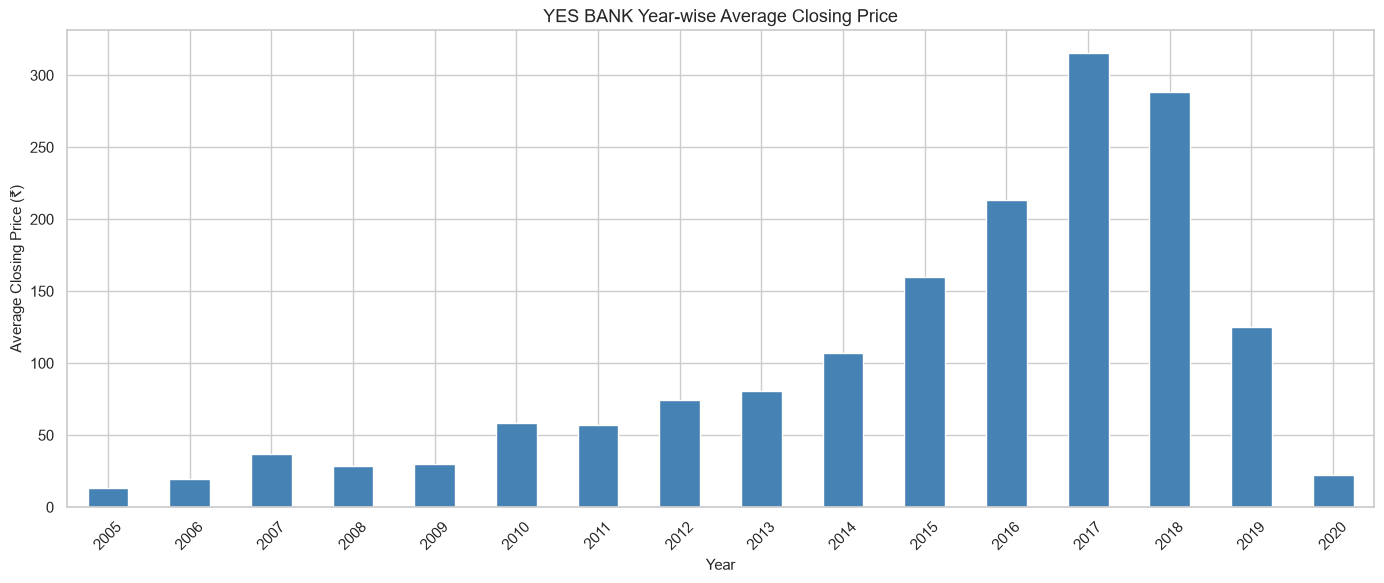

In [21]:
# Chart 8: Compare annual average closing-price levels.
yearly_average_close = df.groupby('Year')['Close'].mean()
plt.figure(figsize=(14, 6))
yearly_average_close.plot(kind='bar', color='steelblue')
plt.title('YES BANK Year-wise Average Closing Price')
plt.xlabel('Year')
plt.ylabel('Average Closing Price (₹)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
plt.close()

**1. Why did you pick the specific chart?**

A bar chart was chosen because it makes annual average closing-price levels easy to compare across calendar years.

**2. What are the insights found from the chart?**

The annual average closing price increases to its highest value of approximately **₹315.31 in 2017**. It falls to approximately **₹288.64 in 2018**, **₹125.26 in 2019**, and **₹22.11 in 2020**. The 2020 value covers January–November only, so it is not a full-year average.

**3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.**

This comparison highlights long-term changes in historical price levels and identifies years for deeper analysis. It can support reporting and exploratory forecasting work. Annual averages conceal within-year movements and should not be interpreted as annual investment returns; partial 2020 coverage also limits direct comparison.

#### Chart 9 — Year-wise Maximum High and Minimum Low

**Chart visualization code**

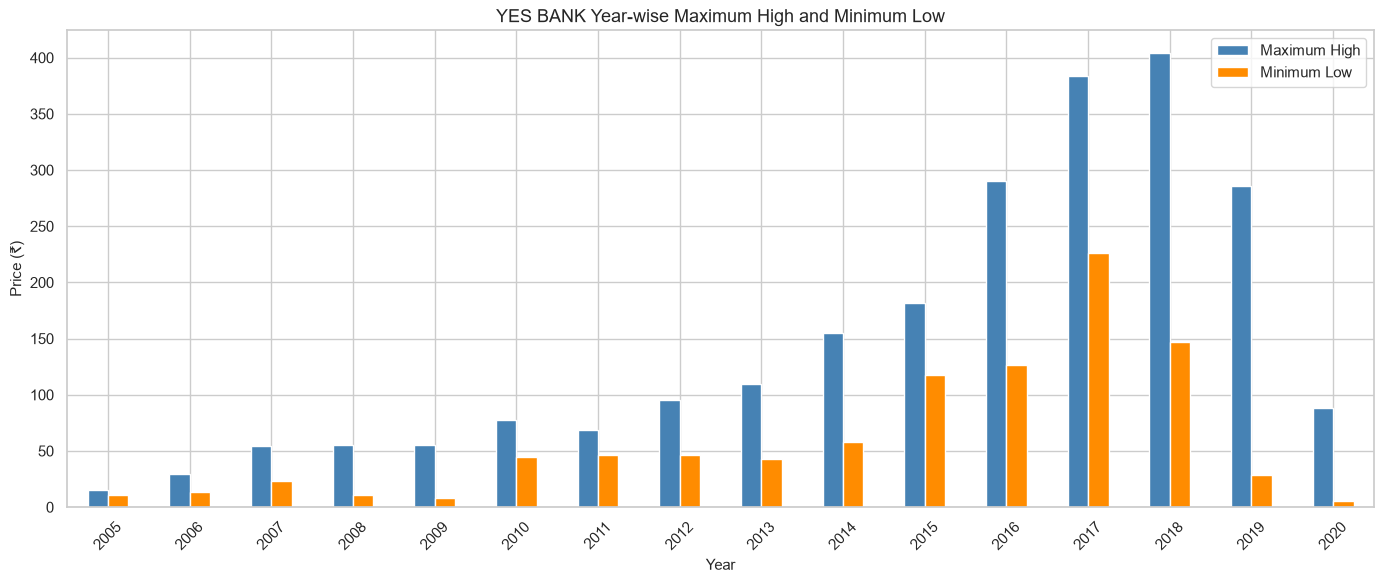

In [22]:
# Chart 9: Compare each year's highest High with its lowest Low.
yearly_extremes = df.groupby('Year').agg(Maximum_High=('High', 'max'), Minimum_Low=('Low', 'min'))
ax = yearly_extremes.plot(kind='bar', figsize=(14, 6), color=['steelblue', 'darkorange'])
ax.set_title('YES BANK Year-wise Maximum High and Minimum Low')
ax.set_xlabel('Year')
ax.set_ylabel('Price (₹)')
ax.legend(['Maximum High', 'Minimum Low'])
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
plt.close()

**1. Why did you pick the specific chart?**

A grouped bar chart was selected to compare the annual upper and lower price extremes. It makes the span between each year's observed maximum and minimum easy to inspect.

**2. What are the insights found from the chart?**

The highest annual `High` in the dataset is **₹404.00 in 2018**. The lowest annual `Low` is **₹5.55 in 2020**. The chart shows a wide span in several years, particularly around the 2017–2019 period. Each bar is an annual extreme, not a typical price.

**3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.**

Annual extremes help identify periods that may deserve detailed risk review. They should not be interpreted as prices available throughout the year or as the return earned by an investor. Extreme observations should be validated and retained when they represent genuine market data.

#### Chart 10 — Opening Price vs Closing Price

**Chart visualization code**

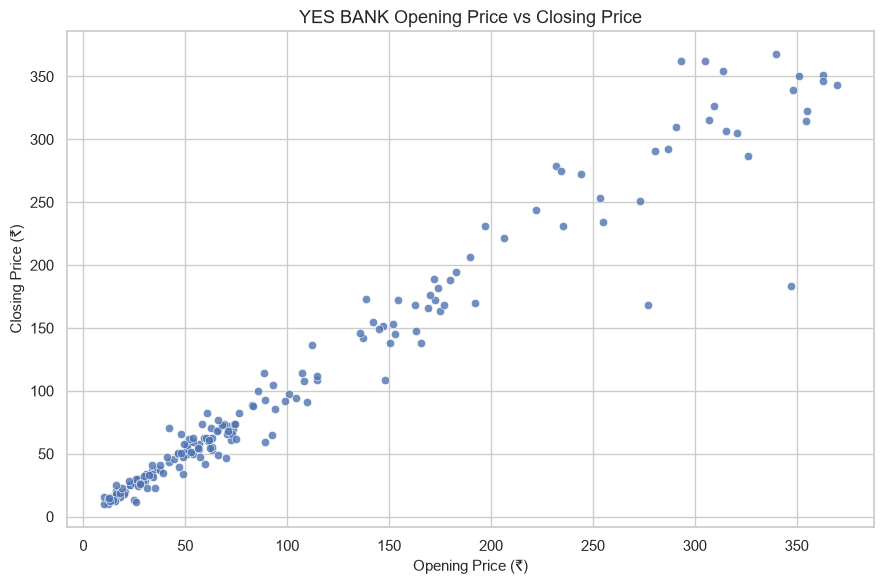

In [23]:
# Chart 10: Explore the association between opening and closing prices.
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x='Open', y='Close', alpha=0.8)
plt.title('YES BANK Opening Price vs Closing Price')
plt.xlabel('Opening Price (₹)')
plt.ylabel('Closing Price (₹)')
plt.tight_layout()
plt.show()
plt.close()

**1. Why did you pick the specific chart?**

A scatter plot was selected to compare two numerical variables and assess whether higher opening prices tend to accompany higher closing prices.

**2. What are the insights found from the chart?**

The relationship is strongly positive; the Pearson correlation is approximately **0.978**. Most observations follow an upward pattern. A few points deviate from the main relationship, showing that the close can differ materially from the open in individual months.

**3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.**

The association can inform feature exploration for a future closing-price model and help identify unusual within-month movements. However, a high correlation between price levels does not imply that opening price alone explains the closing price or that the relationship will remain stable out of sample.

#### Chart 11 — Highest Price vs Lowest Price

**Chart visualization code**

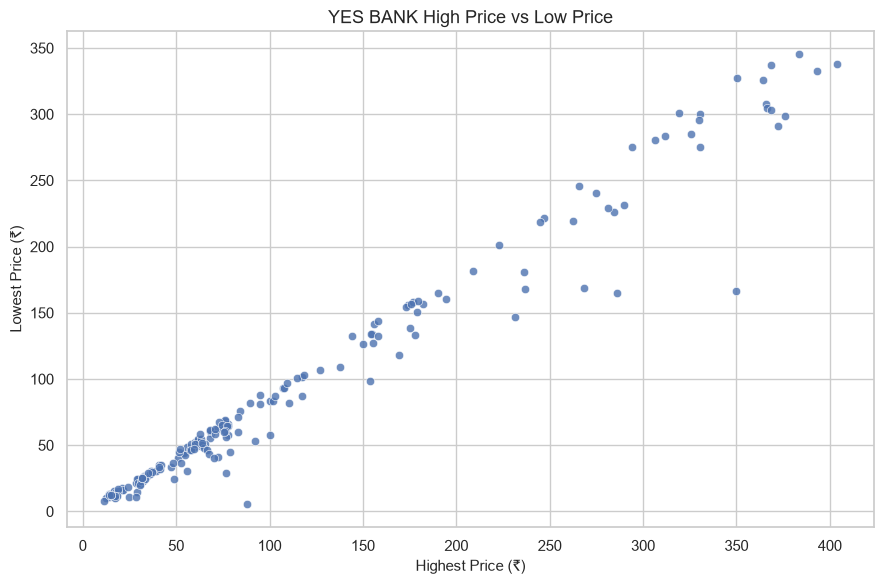

In [24]:
# Chart 11: Examine how monthly highs and lows move together.
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x='High', y='Low', alpha=0.8)
plt.title('YES BANK High Price vs Low Price')
plt.xlabel('Highest Price (₹)')
plt.ylabel('Lowest Price (₹)')
plt.tight_layout()
plt.show()
plt.close()

**1. Why did you pick the specific chart?**

A scatter plot was selected to investigate the relationship between the monthly highest and lowest prices. Both are numerical measures from the same monthly observation.

**2. What are the insights found from the chart?**

The association is very strongly positive, with a Pearson correlation of approximately **0.983**. Higher-price months generally have higher highs and higher lows. This largely reflects common changes in the stock's overall price level across the observation period.

**3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.**

The relationship helps validate that the OHLC fields move consistently and supports exploratory feature analysis. The high correlation also signals overlapping information among price-level features; a future regression model should assess multicollinearity and use time-based evaluation.

#### Chart 12 — Trading Range vs Closing Price

**Chart visualization code**

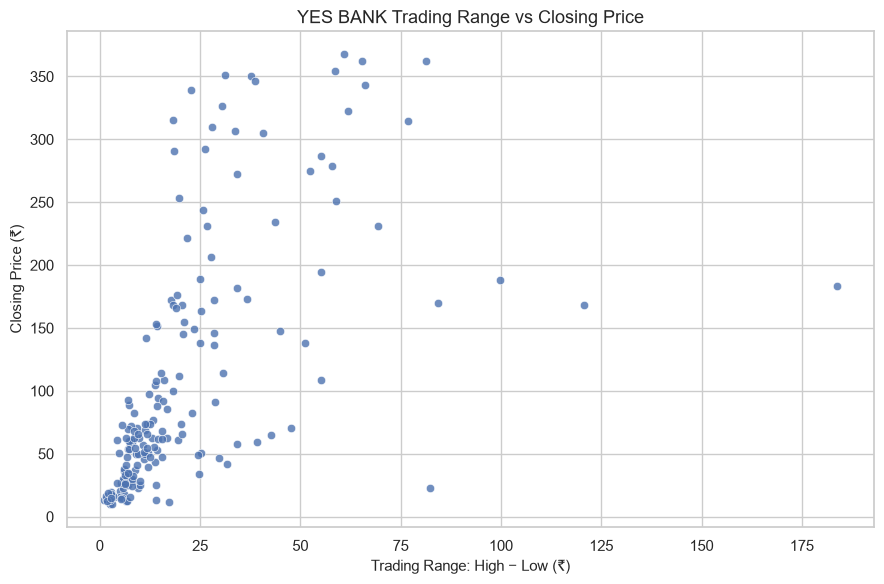

In [25]:
# Chart 12: Compare absolute monthly trading range with the closing-price level.
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x='Price_Range', y='Close', alpha=0.8)
plt.title('YES BANK Trading Range vs Closing Price')
plt.xlabel('Trading Range: High − Low (₹)')
plt.ylabel('Closing Price (₹)')
plt.tight_layout()
plt.show()
plt.close()

**1. Why did you pick the specific chart?**

A scatter plot was chosen to explore the association between the absolute high-low range and the closing-price level. It can reveal clusters and unusually wide monthly ranges.

**2. What are the insights found from the chart?**

The relationship is moderately positive (Pearson correlation approximately **0.595**): higher closing-price levels are often associated with larger absolute ranges, but the points are dispersed. The widest observed range is **₹183.85 in September 2018**.

**3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.**

This view helps locate observations with large absolute movement and motivates using percentage-based range measures when comparing different price regimes. A larger rupee range is not automatically greater proportional risk, and the chart does not indicate whether a month gained or lost value.

#### Chart 13 — Month-wise Average Closing Price

**Chart visualization code**

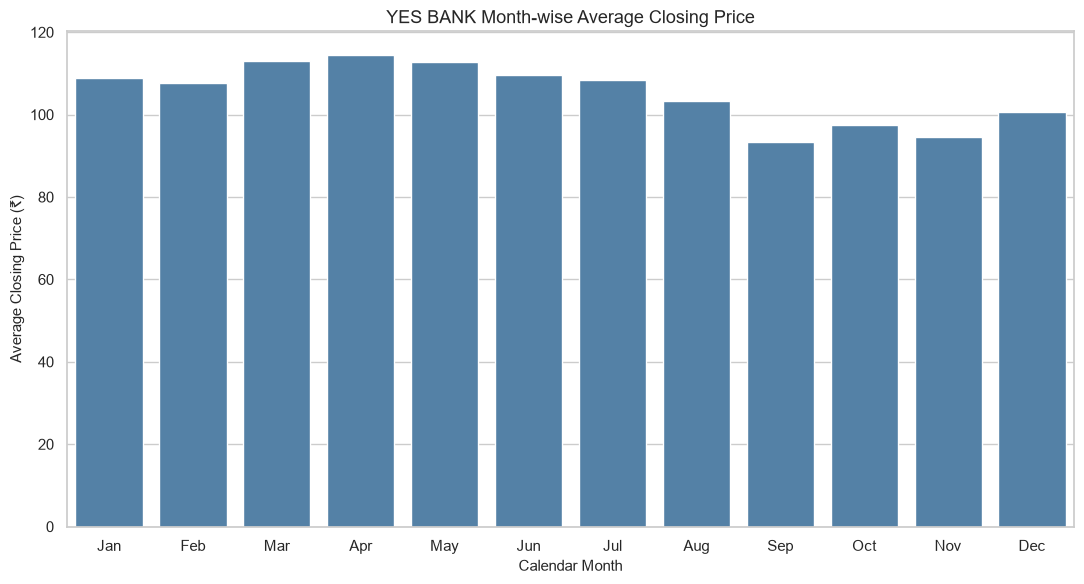

In [26]:
# Chart 13: Compare the average closing price for each calendar month across all years.
monthly_average_close = df.groupby('Month')['Close'].mean().reindex(range(1, 13))
month_labels = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
plt.figure(figsize=(11, 6))
sns.barplot(x=monthly_average_close.index, y=monthly_average_close.values, color='steelblue')
plt.title('YES BANK Month-wise Average Closing Price')
plt.xlabel('Calendar Month')
plt.ylabel('Average Closing Price (₹)')
plt.xticks(ticks=np.arange(12), labels=month_labels)
plt.tight_layout()
plt.show()
plt.close()

**1. Why did you pick the specific chart?**

A bar chart was chosen to compare the average closing-price level for each calendar month across the full dataset. It provides a first look at possible month-of-year differences.

**2. What are the insights found from the chart?**

The month-wise averages range from approximately **₹93.34 in September** to **₹114.45 in April**. These averages combine observations from 2005–2020, so they also reflect the long-term changes in the stock's price level. They do not, by themselves, establish a repeatable seasonal effect.

**3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.**

The chart can motivate more careful seasonal analysis and help describe the dataset. A client should not use this plot alone to time trades because month averages are confounded by the long-term price trend and the limited number of observations for each month.

#### Chart 14 — Year-wise Average Monthly Returns

**Chart visualization code**

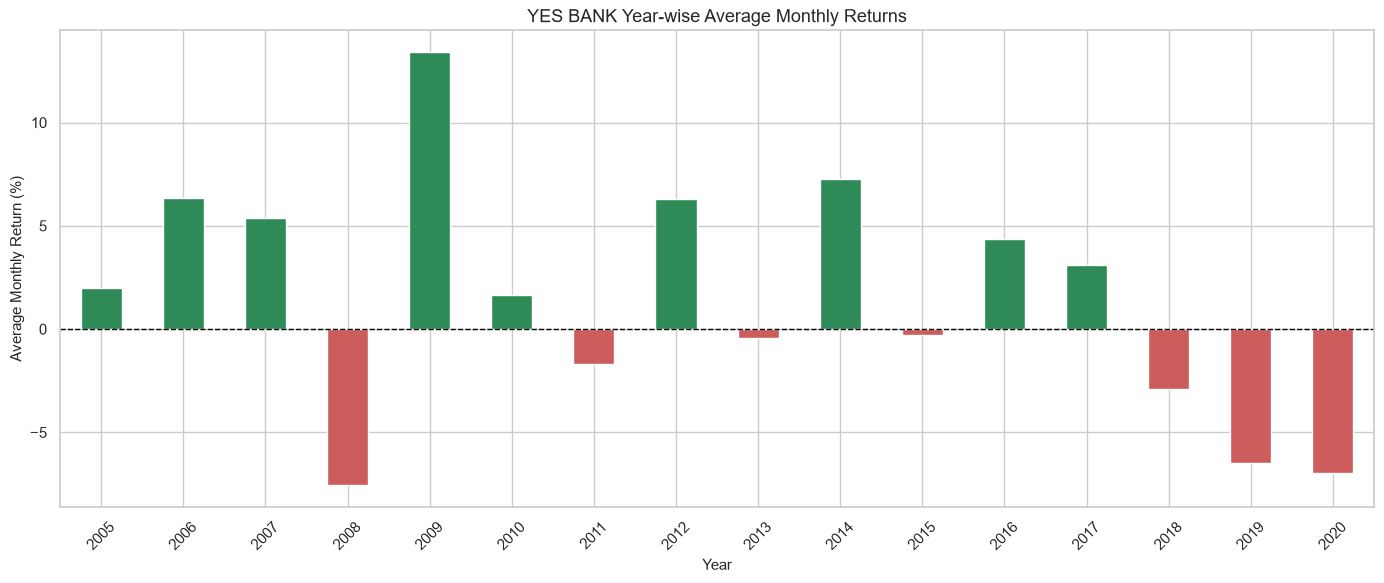

In [27]:
# Chart 14: Compare average month-over-month returns by calendar year.
yearly_average_return = df.groupby('Year')['Monthly_Return'].mean()
plt.figure(figsize=(14, 6))
yearly_average_return.plot(kind='bar', color=np.where(yearly_average_return >= 0, 'seagreen', 'indianred'))
plt.axhline(0, color='black', linestyle='--', linewidth=1)
plt.title('YES BANK Year-wise Average Monthly Returns')
plt.xlabel('Year')
plt.ylabel('Average Monthly Return (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
plt.close()

**1. Why did you pick the specific chart?**

A bar chart with a zero reference line was selected to compare average monthly returns by year and distinguish positive from negative average returns.

**2. What are the insights found from the chart?**

The highest annual average monthly return is approximately **13.41% in 2009**. The lowest is approximately **−7.57% in 2008**. Average monthly returns are also negative in **2018 (−2.88%)**, **2019 (−6.50%)**, and **2020 (−6.95%)**. The 2020 figure is based on January–November observations.

**3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.**

The comparison identifies years with relatively favourable or unfavourable average monthly returns and can guide historical review. Averaging monthly returns is not the same as calculating a compounded annual return; the chart should be treated as a descriptive summary rather than a realized annual investment performance measure.

#### Chart 15 — Month-wise Distribution of Monthly Returns

**Chart visualization code**

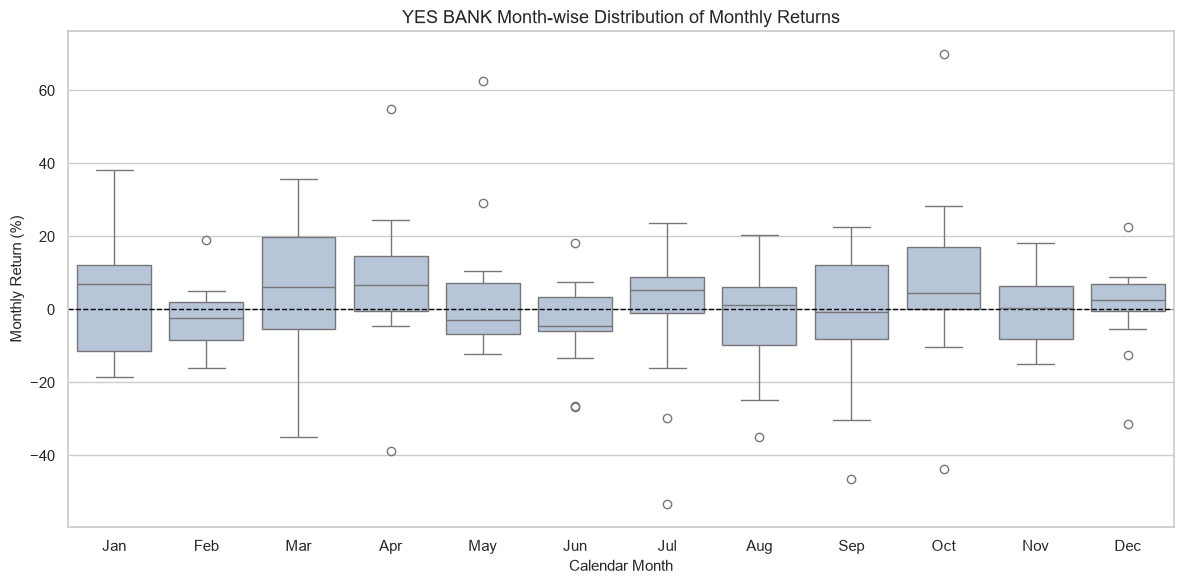

In [28]:
# Chart 15: Compare the spread of monthly returns across calendar months.
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='Month', y='Monthly_Return', order=list(range(1, 13)), color='lightsteelblue')
plt.axhline(0, color='black', linestyle='--', linewidth=1)
plt.title('YES BANK Month-wise Distribution of Monthly Returns')
plt.xlabel('Calendar Month')
plt.ylabel('Monthly Return (%)')
plt.xticks(ticks=np.arange(12), labels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.tight_layout()
plt.show()
plt.close()

**1. Why did you pick the specific chart?**

A box plot was selected to compare the distribution, median, spread, and potential extreme returns for each calendar month. It is more informative than comparing monthly means alone.

**2. What are the insights found from the chart?**

The medians vary by calendar month; for example, the January median is approximately **6.91%**, while the June median is approximately **−4.49%**. The boxes and whiskers also show that return variability is present within months, rather than being captured by a single average. Each month has relatively few observations because the series is monthly.

**3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.**

The chart can help investigate whether calendar-month effects merit further statistical testing. The limited number of observations per month and the changing market regime mean that apparent month differences may be unstable; they should not be treated as a reliable seasonal trading signal without out-of-sample validation.

#### Chart 16 — 12-Month Rolling Volatility Over Time

**Chart visualization code**

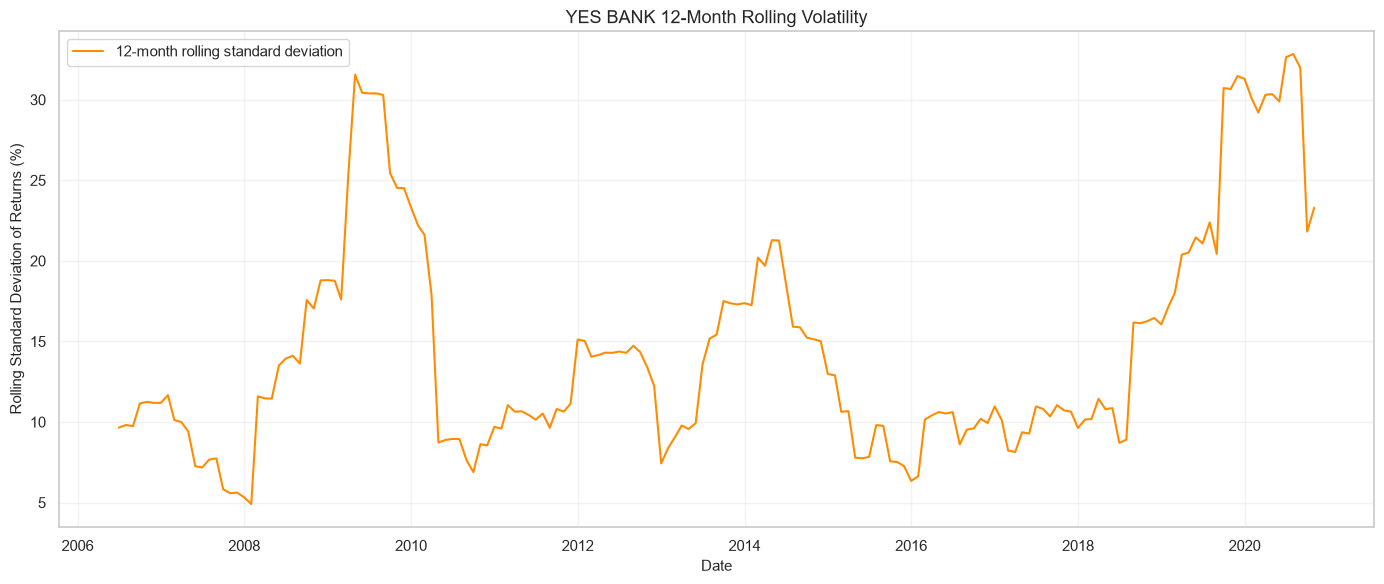

In [29]:
# Chart 16: Show how trailing return variability changes through time.
plt.figure(figsize=(14, 6))
plt.plot(df['Date'], df['Rolling_Volatility'], label='12-month rolling standard deviation', color='darkorange')
plt.title('YES BANK 12-Month Rolling Volatility')
plt.xlabel('Date')
plt.ylabel('Rolling Standard Deviation of Returns (%)')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()
plt.close()

**1. Why did you pick the specific chart?**

A line chart was selected because volatility is time-dependent. A trailing 12-month standard deviation smooths individual monthly returns and tracks how return variability changes over time.

**2. What are the insights found from the chart?**

Rolling volatility ranges from approximately **4.91% in February 2008** to **32.84% in August 2020**. Elevated volatility is visible around 2009 and again near the end of the sample. The statistic is undefined until a full 12-month return window is available.

**3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.**

Monitoring rolling volatility can support historical risk review and stress testing. Increases indicate wider variation in recent returns, but do not determine direction: high volatility can occur during rallies or declines. The chart is based on the historical sample ending in November 2020 and is not a current risk estimate.

#### Chart 17 — Closing Price with 6- and 12-Month Moving Averages

**Chart visualization code**

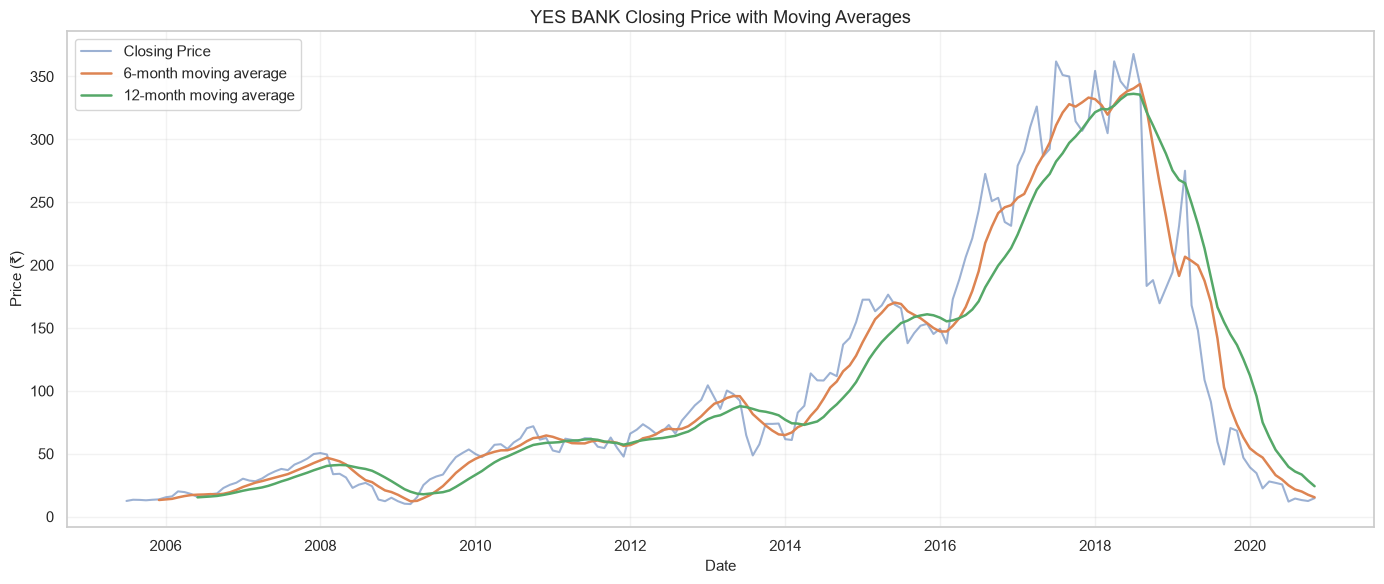

In [30]:
# Chart 17: Compare observed closing prices with trailing moving averages.
plt.figure(figsize=(14, 6))
plt.plot(df['Date'], df['Close'], label='Closing Price', alpha=0.55)
plt.plot(df['Date'], df['MA_6'], label='6-month moving average', linewidth=1.8)
plt.plot(df['Date'], df['MA_12'], label='12-month moving average', linewidth=1.8)
plt.title('YES BANK Closing Price with Moving Averages')
plt.xlabel('Date')
plt.ylabel('Price (₹)')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()
plt.close()

**1. Why did you pick the specific chart?**

A line chart with trailing 6- and 12-month moving averages was chosen to smooth short-term fluctuations and compare faster and slower trend measures. The shorter moving average reacts more quickly to new observations.

**2. What are the insights found from the chart?**

The closing price peaks at **₹367.90 in July 2018**, then falls sharply over the remaining sample. Both moving averages turn down after the high-price period; the 6-month average responds faster than the 12-month average. The first five and eleven moving-average values, respectively, are undefined because a full window is not yet available.

**3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.**

Moving averages provide a simple descriptive trend filter and can help flag changes in historical direction. They are lagging indicators, not guaranteed signals, and their use in a predictive model must avoid look-ahead bias. A moving average calculated with future data would be invalid; this notebook uses trailing windows only.

#### Chart 18 — Percentage Trading Range vs Absolute Monthly Return

**Chart visualization code**

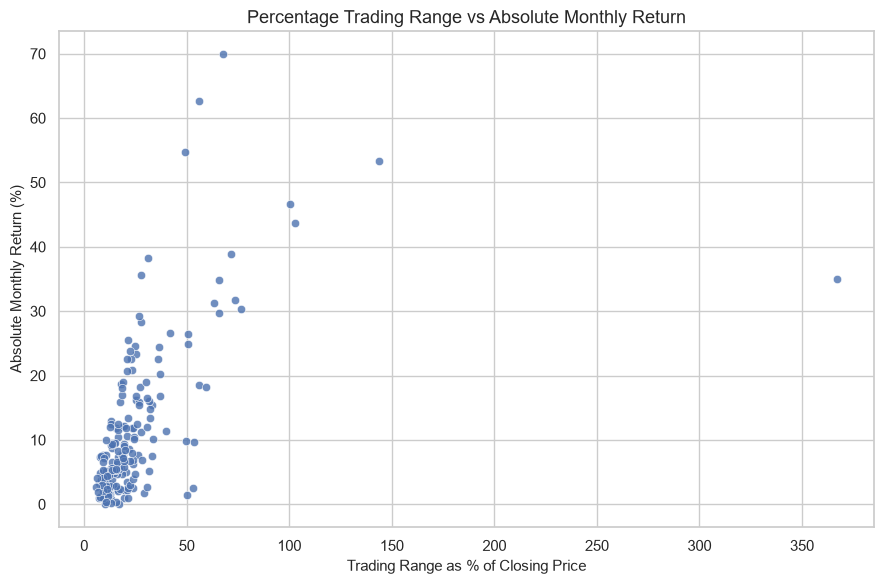

In [31]:
# Chart 18: Compare relative within-month range with the magnitude of monthly return.
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x='Price_Range_Pct', y='Absolute_Return', alpha=0.8)
plt.title('Percentage Trading Range vs Absolute Monthly Return')
plt.xlabel('Trading Range as % of Closing Price')
plt.ylabel('Absolute Monthly Return (%)')
plt.tight_layout()
plt.show()
plt.close()

**1. Why did you pick the specific chart?**

A scatter plot was selected to compare two scale-adjusted measures of movement: high-low range as a percentage of close, and the absolute month-over-month closing return. Absolute return focuses on movement magnitude rather than direction.

**2. What are the insights found from the chart?**

The two measures have a moderate positive association (Pearson correlation approximately **0.55**). Larger relative trading ranges therefore tend to accompany larger absolute monthly closing returns, although the relationship is not exact and points are dispersed.

**3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.**

The comparison helps analysts examine whether wider within-month price movement is accompanied by larger close-to-close movement. It can inform risk-feature design, but correlation is not causation and the chart does not distinguish positive from negative returns because absolute returns remove direction.

### M — Multivariate Analysis

#### Chart 19 — Correlation Heatmap of OHLC Variables

**Chart visualization code**

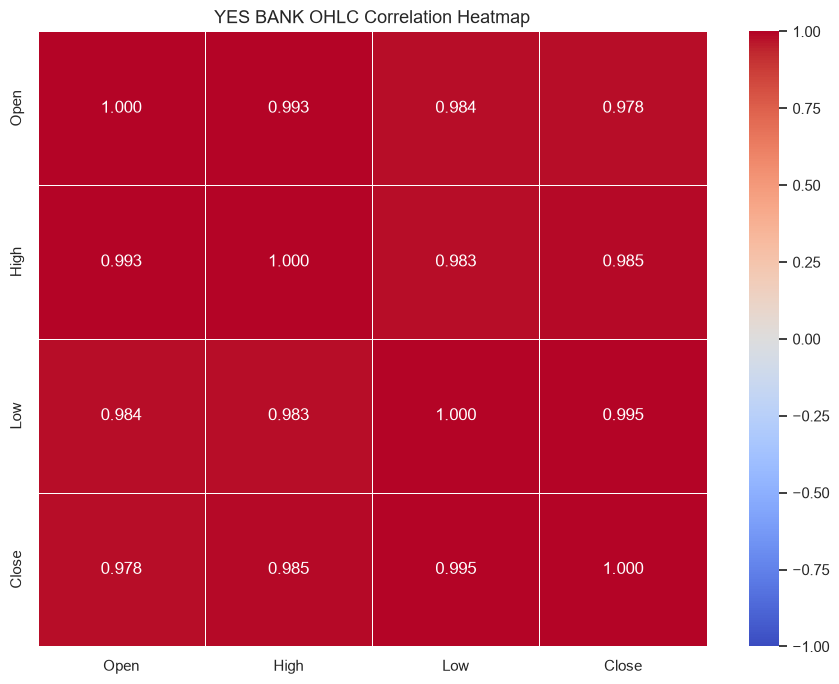

In [32]:
# Chart 19: Pearson correlations among the four original numerical price variables.
ohlc_columns = ['Open', 'High', 'Low', 'Close']
correlation_ohlc = df[ohlc_columns].corr(method='pearson')
plt.figure(figsize=(9, 7))
sns.heatmap(correlation_ohlc, annot=True, cmap='coolwarm', fmt='.3f', vmin=-1, vmax=1, linewidths=0.5)
plt.title('YES BANK OHLC Correlation Heatmap')
plt.tight_layout()
plt.show()
plt.close()

**1. Why did you pick the specific chart?**

A correlation heatmap was selected to summarize the direction and strength of all pairwise linear relationships among the four OHLC variables in a compact matrix.

**2. What are the insights found from the chart?**

All off-diagonal correlations are very high and positive, ranging from approximately **0.978 (Open–Close)** to **0.995 (Low–Close)**. High–Low correlation is approximately **0.983**, and High–Close is approximately **0.985**. These variables move together strongly because they measure the same stock's price level during each month.

**3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.**

The heatmap helps identify redundancy among candidate predictors and alerts analysts to potential multicollinearity in linear models. A high correlation does not establish causality and may partly reflect the shared long-term price trend. Future models should assess feature redundancy and use chronological validation.

#### Chart 20 — Pair Plot of OHLC Variables

**Chart visualization code**

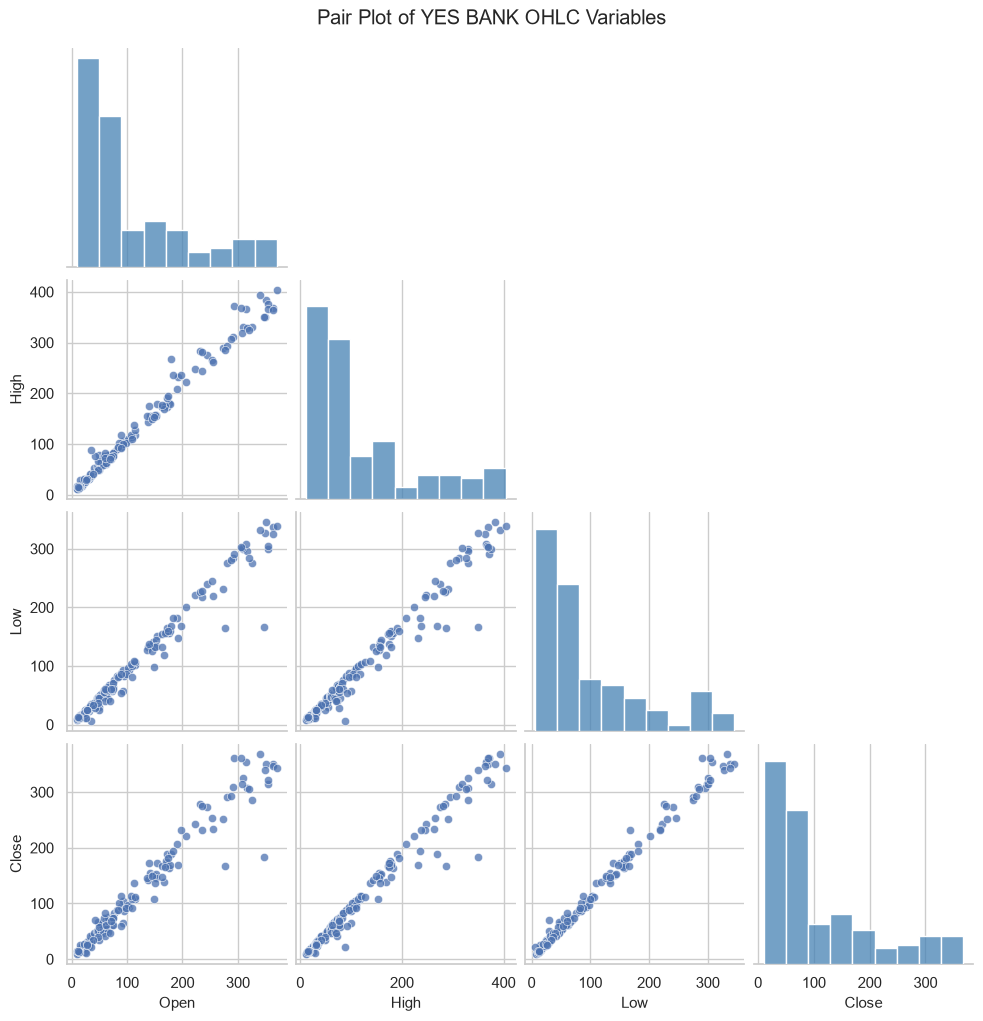

In [33]:
# Chart 20: Show pairwise scatter plots and one-variable distributions for OHLC fields.
pair_grid = sns.pairplot(
    df[ohlc_columns],
    diag_kind='hist',
    diag_kws={'color': 'steelblue'},
    corner=True,
    plot_kws={'alpha': 0.75, 's': 35}
)
pair_grid.fig.suptitle('Pair Plot of YES BANK OHLC Variables', y=1.02)
plt.show()
plt.close('all')

**1. Why did you pick the specific chart?**

A pair plot was selected because it combines pairwise scatter plots with univariate distributions. It provides a broader view of relationships and possible clusters than a single two-variable chart.

**2. What are the insights found from the chart?**

The pairwise panels show strong positive, approximately linear associations among OHLC variables, consistent with the correlation matrix. The diagonal histograms show the distributions of each variable, which are right-skewed because the dataset spans a wide range of historical price levels. A few observations sit away from the main point patterns.

**3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.**

The plot supports feature review and helps identify unusual observations for validation. Strongly associated features may provide overlapping information in a predictive model. Any unusual point should be checked against the source data before it is removed or treated as an error.

#### Chart 21 — Year-by-Month Closing Price Heatmap

**Chart visualization code**

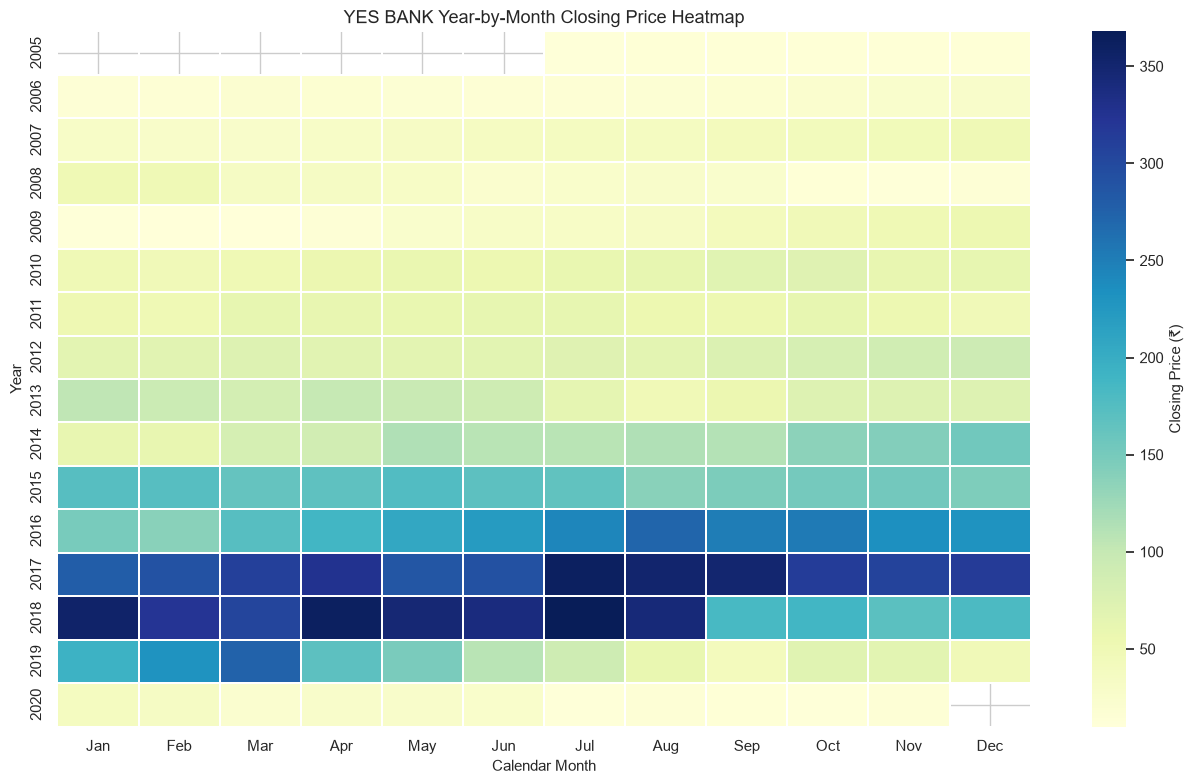

In [34]:
# Chart 21: Combine year and calendar month to inspect price levels over time.
year_month_prices = df.pivot_table(index='Year', columns='Month', values='Close', aggfunc='mean')
plt.figure(figsize=(13, 8))
sns.heatmap(year_month_prices, cmap='YlGnBu', annot=False, linewidths=0.25, cbar_kws={'label': 'Closing Price (₹)'})
plt.title('YES BANK Year-by-Month Closing Price Heatmap')
plt.xlabel('Calendar Month')
plt.ylabel('Year')
plt.xticks(ticks=np.arange(12) + 0.5, labels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'], rotation=0)
plt.tight_layout()
plt.show()
plt.close()

**1. Why did you pick the specific chart?**

A two-dimensional heatmap was selected to combine year and calendar month while encoding closing-price level with colour. This makes long-term price regimes visible while retaining month-level detail.

**2. What are the insights found from the chart?**

The heatmap highlights the increase in price levels into 2017–2018 and the subsequent decline through 2019–2020. The 2005 row begins in July and the 2020 row ends in November, so blank cells at the beginning and end represent months not present in the source file, not missing observations within the observed period.

**3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.**

This view is useful for presenting temporal patterns and checking whether apparent month-of-year effects are actually driven by broader multi-year trends. The strong year effect means month-level colours should not be interpreted as evidence of seasonality without a separate, appropriate test.

#### Chart 22 — Correlation Heatmap of Engineered Features

**Chart visualization code**

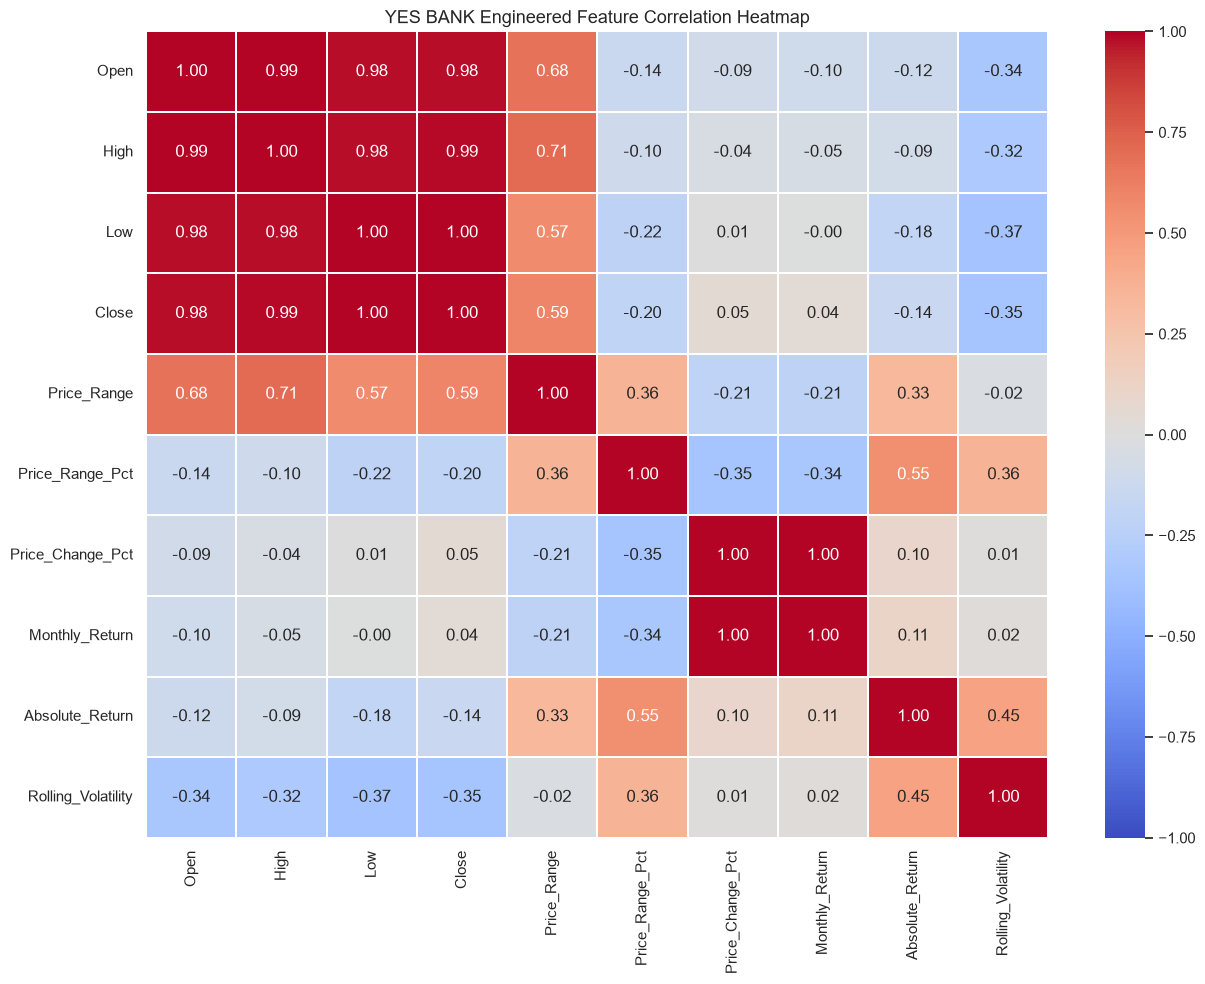

In [35]:
# Chart 22: Review relationships among original prices and engineered movement/risk features.
engineered_columns = [
    'Open', 'High', 'Low', 'Close', 'Price_Range', 'Price_Range_Pct',
    'Price_Change_Pct', 'Monthly_Return', 'Absolute_Return', 'Rolling_Volatility'
]
engineered_correlation = df[engineered_columns].corr(method='pearson')
plt.figure(figsize=(13, 10))
sns.heatmap(engineered_correlation, cmap='coolwarm', center=0, vmin=-1, vmax=1, annot=True, fmt='.2f', linewidths=0.3)
plt.title('YES BANK Engineered Feature Correlation Heatmap')
plt.tight_layout()
plt.show()
plt.close()

**1. Why did you pick the specific chart?**

A multivariate correlation heatmap was selected to inspect linear relationships across original OHLC prices and engineered measures of price range, return, and rolling volatility. It supports feature review before a later forecasting exercise.

**2. What are the insights found from the chart?**

The OHLC level variables remain very strongly correlated. The engineered return and volatility features measure different aspects of behaviour and are not interchangeable with price levels. Percentage trading range and absolute monthly return show a positive association, while rolling volatility summarizes trailing variability rather than return direction. Correlations are pairwise and may be based on fewer rows where rolling values are undefined.

**3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.**

The chart helps identify redundant predictors and distinguish price-level information from movement and risk information. It also warns against selecting features solely because they correlate strongly with the target on the full dataset. Feature selection must be performed using training data only, and all validation must preserve chronological order to avoid leakage.

## 5. Solution to the Business Objective

### What do you suggest the client do to achieve the business objective?

1. **Maintain a validated time-series dataset.** Preserve the monthly date index, validate OHLC ordering, document source updates, and monitor missing or duplicated observations whenever new data is appended.
2. **Separate price level, return, and risk.** Analyze closing-price level alongside month-over-month return, percentage trading range, and rolling volatility. These measure different concepts and should not be treated as substitutes.
3. **Address feature redundancy.** The OHLC fields are strongly correlated. Before fitting a linear model, inspect multicollinearity and consider selecting a subset of features or using regularization. Do not assume that adding every OHLC variable improves generalization.
4. **Use a time-aware modelling design.** If the project proceeds to forecasting, define the prediction horizon first, construct predictors using only information available at the forecast origin, and use chronological train/validation/test splits or walk-forward validation. Avoid random splitting and future-derived features.
5. **Establish simple baselines.** Compare any machine-learning model with a naïve baseline, such as predicting the next close from the latest available close. Report MAE and RMSE (and optionally MAPE only when its denominator is appropriate) on held-out future periods.
6. **Monitor uncertainty and model drift.** Track prediction errors and volatility over time. Reassess the model when market behaviour changes; historical fit alone is not evidence of current accuracy.
7. **Use the findings for analysis, not guaranteed trading decisions.** The data contains only monthly OHLC values. Add volume, corporate actions, benchmark returns, fundamentals, macroeconomic variables, and event data only when reliable sources are available and their timestamps can be aligned without leakage.

The analysis supports historical understanding and the design of a future forecasting workflow. It does not, by itself, demonstrate a predictive model's accuracy or provide investment advice.

## Conclusion

The EDA examined 185 monthly YES BANK observations from July 2005 through November 2020. The source dataset contains five fields—Date, Open, High, Low, and Close—and the supplied file has no missing values or duplicate rows. Data validation confirmed positive price values and consistent OHLC ordering. Chronological sorting and feature engineering produced calendar fields, price ranges, price changes, monthly returns, moving averages, and rolling volatility measures.

The visual analysis shows that closing-price levels changed substantially over the observation period. The annual average closing price reached its highest level in 2017 at approximately ₹315.31, followed by a marked decline in the later years. The 2020 observations cover January through November only. The closing-price distribution is right-skewed, and the OHLC variables are very strongly positively correlated, indicating that they share substantial price-level information.

Return and volatility charts show that monthly performance varied considerably, including both large positive and negative returns. The observed monthly return range is approximately −53.32% to +69.96%, while twelve-month rolling volatility ranges from approximately 4.91% to 32.84%. These measures help describe historical variability but do not explain its causes or predict future outcomes. The year-month heatmap also shows why month-of-year averages should be interpreted cautiously: long-term changes in price level can dominate apparent calendar effects.

Overall, the notebook provides a reproducible foundation for further financial data analysis. A future forecasting phase should use leakage-safe features, time-based validation, simple baselines, suitable error metrics, and ongoing monitoring. Historical patterns should not be interpreted as guaranteed future performance or as investment advice.

### Scope and Limitations

- The dataset ends in **November 2020**; this notebook does not contain current YES BANK market data.
- The dataset is monthly and includes only OHLC prices. It does not include daily price paths, trading volume, dividends, corporate actions, company fundamentals, benchmark indices, or news events.
- The source CSV does not specify currency metadata; ₹ labels follow the assignment context and should be confirmed before external use.
- Correlations and visual patterns are descriptive and do not establish causation.
- No forecasting model is trained or evaluated in this EDA notebook. Prediction performance must be assessed separately on unseen future observations.